# A2 – Rentabilidad y comportamiento de compra

El enunciado pide cuatro cosas para A2:

1. Qué segmentos de clientes, categorías de producto y canales de venta aportan más y menos al **margen bruto** total.
2. El valor de un cliente a lo largo del tiempo (CLV) por segmento, y cuáles segmentos están en declive.
3. La estacionalidad de las ventas: picos, valles y tendencias por categoría y por canal.
4. Si los descuentos generan volumen suficiente para compensar el margen que se pierde.

Usamos los datos limpios de A1 (`cargar_limpio`). Los montos están en unidades monetarias (u. m.): ni el enunciado ni los datos dicen la moneda.

**Sobre el segmento:** el segmento que trae el archivo es una franja del número de compras de cada cliente en los 24 meses (A1.4). Lo usamos para describir quién aporta el margen, como pide el enunciado. Cuando una cifra depende de predecir qué hará un cliente (retención, CLV), la comprobamos también con grupos que se conocen en el momento de la predicción.

Cómo calculamos cada cosa, y qué está pendiente de confirmar con el profesor, está en `DECISIONES.md`, sección A2.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from src.carga import cargar_limpio, RAIZ

d = cargar_limpio()
cli = d["clientes"]
trx = d["transacciones"].merge(cli[["cliente_id", "segmento"]], on="cliente_id")
trx["anio"] = trx.fecha.dt.year
FIG = RAIZ / "figures"

# Colores (paleta de referencia de la guía de visualización)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
TEXTO, TEXTO_2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def miles(x):
    # 1.234 en vez de 1,234
    return f"{x:,.0f}".replace(",", ".")

## 1. Margen bruto y margen neto

- **Margen bruto:** lo que se vendió menos lo que costaron los productos. Es lo que pide el enunciado.
- **Margen neto:** el margen bruto después de restar las devoluciones. Si una venta se devuelve, se reembolsa completa. Si el producto vuelve en buen estado, se revende y solo se pierde el margen de esa venta. Si es defectuoso o un fraude, se pierde también el costo del producto.

También calculamos cuánto margen se regaló en descuentos.

In [2]:
ventas = trx.monto_neto.sum()
bruto = trx.margen_bruto.sum()
neto = trx.margen_neto.sum()
regalado = trx.costo_descuento.sum()

devueltas = trx[trx.devuelta]
perdido_revendible = devueltas.loc[~devueltas.motivo_devolucion.isin(["Producto_defectuoso", "Fraude_reportado"]), "margen_bruto"].sum()
perdido_costo = bruto - neto - perdido_revendible

print(f"Ventas: {ventas:,.0f}")
print(f"Margen bruto: {bruto:,.0f} ({bruto / ventas:.1%} de las ventas)")
print(f"Margen neto (después de devoluciones): {neto:,.0f} ({neto / ventas:.1%} de las ventas)")
print(f"Las devoluciones se llevan {bruto - neto:,.0f}, el {(bruto - neto) / bruto:.1%} del margen bruto:")
print(f"   margen de ventas devueltas que se revenden: {perdido_revendible:,.0f}")
print(f"   productos defectuosos o fraude (margen + costo): {perdido_costo:,.0f}")
print(f"Descuentos regalados: {regalado:,.0f}. Sin descuentos, el margen bruto habría sido {bruto + regalado:,.0f}: "
      f"los descuentos se llevan el {regalado / (bruto + regalado):.1%}")
print(f"% de ventas devueltas (en monto): {devueltas.monto_neto.sum() / ventas:.1%}")

Ventas: 17,392,987
Margen bruto: 4,310,329 (24.8% de las ventas)
Margen neto (después de devoluciones): 3,123,230 (18.0% de las ventas)
Las devoluciones se llevan 1,187,099, el 27.5% del margen bruto:
   margen de ventas devueltas que se revenden: 399,501
   productos defectuosos o fraude (margen + costo): 787,598
Descuentos regalados: 967,701. Sin descuentos, el margen bruto habría sido 5,278,030: los descuentos se llevan el 18.3%
% de ventas devueltas (en monto): 14.6%


In [3]:
# ¿El margen está cayendo? Margen bruto y neto por trimestre
q = trx.groupby("trimestre").agg(ventas=("monto_neto", "sum"), bruto=("margen_bruto", "sum"), neto=("margen_neto", "sum"))
margen_trimestre = pd.DataFrame({"ventas": q.ventas.round(0), "margen bruto %": (100 * q.bruto / q.ventas).round(1),
                                 "margen neto %": (100 * q.neto / q.ventas).round(1)})
print(margen_trimestre.T.to_string())

# Sensibilidad del supuesto A2.1: ¿y si el proveedor se hace cargo de los defectuosos?
perdido_si_proveedor = devueltas.margen_bruto.sum()
print(f"\nMargen que se llevan las devoluciones con nuestro supuesto: {bruto - neto:,.0f} ({(bruto - neto) / bruto:.1%} del margen bruto)")
print(f"Si el proveedor asume los defectuosos (solo se pierde el margen de la venta): {perdido_si_proveedor:,.0f} ({perdido_si_proveedor / bruto:.1%})")
print(f"El supuesto 'el defectuoso se pierde' explica {perdido_costo / (bruto - neto):.0%} de lo que se llevan las devoluciones")

trimestre          2023Q1     2023Q2     2023Q3     2023Q4     2024Q1     2024Q2     2024Q3     2024Q4
ventas          2117673.0  2165578.0  2234694.0  2190462.0  2151260.0  2167262.0  2180895.0  2185164.0
margen bruto %       24.6       24.7       24.7       24.6       25.4       24.9       24.7       24.7
margen neto %        17.5       17.9       18.6       17.7       17.4       18.4       18.3       17.9

Margen que se llevan las devoluciones con nuestro supuesto: 1,187,099 (27.5% del margen bruto)
Si el proveedor asume los defectuosos (solo se pierde el margen de la venta): 580,278 (13.5%)
El supuesto 'el defectuoso se pierde' explica 66% de lo que se llevan las devoluciones


**El margen no cae.** El margen bruto se mantiene entre 24,6% y 25,4% en los ocho trimestres, y el neto entre 17,4% y 18,6%. La "presión creciente en los márgenes" del enunciado no aparece en los datos (A1). El problema es de nivel: dónde se va el margen todos los trimestres.

**Cuánto pesa el supuesto A2.1.** Que las devoluciones se lleven el 27,5% del margen depende sobre todo de suponer que el producto defectuoso se pierde (la empresa asume su costo). Si el proveedor lo repone, las devoluciones se llevan la mitad: 13,5%. Por eso damos las dos cifras y está en la lista de preguntas al profesor.

## 2. Quién aporta el margen

Para cada segmento, categoría y canal mostramos qué parte de las ventas, del margen bruto y del margen neto le corresponde. Si una categoría aporta mucho más a las ventas que al margen, vende mucho pero gana poco.

In [4]:
def aporte(col):
    g = trx.groupby(col).agg(ventas=("monto_neto", "sum"), margen_bruto=("margen_bruto", "sum"),
                             margen_neto=("margen_neto", "sum"), devuelto=("monto_neto", lambda s: s[trx.loc[s.index, "devuelta"]].sum()))
    t = pd.DataFrame({
        "% de las ventas": 100 * g.ventas / g.ventas.sum(),
        "% del margen bruto": 100 * g.margen_bruto / g.margen_bruto.sum(),
        "% del margen neto": 100 * g.margen_neto / g.margen_neto.sum(),
        "margen bruto %": 100 * g.margen_bruto / g.ventas,
        "margen neto %": 100 * g.margen_neto / g.ventas,
        "% devuelto": 100 * g.devuelto / g.ventas,
        "margen bruto": g.margen_bruto,
    })
    return t.sort_values("% del margen bruto", ascending=False).round(1)

tablas = {col: aporte(col) for col in ["segmento", "categoria", "canal"]}
for col, t in tablas.items():
    print(f"\n=== Por {col}")
    print(t.to_string())
    assert abs(t["margen bruto"].sum() - bruto) < 1


=== Por segmento
            % de las ventas  % del margen bruto  % del margen neto  margen bruto %  margen neto %  % devuelto  margen bruto
segmento                                                                                                                   
Frecuente              50.4                49.5               49.0            24.3           17.5        14.8     2131971.0
Premium                30.4                31.2               31.9            25.5           18.8        13.9     1345562.6
Esporádico             15.5                15.6               15.5            25.0           17.9        15.1      674499.2
Nuevo                   1.9                 1.9                2.1            24.7           20.0        13.2       80590.2
Inactivo                1.8                 1.8                1.6            24.5           15.5        16.8       77706.0

=== Por categoria
                     % de las ventas  % del margen bruto  % del margen neto  margen bruto %  ma

In [5]:
matriz = trx.pivot_table(index="categoria", columns="canal", values="margen_bruto", aggfunc="sum")
print("% del margen bruto total, por categoría y canal:")
print((100 * matriz / bruto).round(1).to_string())

tasa = trx.pivot_table(index="categoria", columns="canal", values="margen_bruto", aggfunc="sum") / \
       trx.pivot_table(index="categoria", columns="canal", values="monto_neto", aggfunc="sum")
print("\nMargen bruto % (margen / ventas), por categoría y canal:")
print((100 * tasa).round(1).to_string())
print("\nDescuento promedio por canal:", (trx.groupby("canal").descuento.mean() * 100).round(1).to_dict())

% del margen bruto total, por categoría y canal:
canal                app_movil  online  tienda_fisica
categoria                                            
Alimentos_y_Bebidas        0.4     0.8            1.0
Belleza_y_Salud            1.2     2.6            3.3
Deportes                   3.7     7.6            9.8
Electrónica                4.4     8.0           12.0
Hogar_y_Deco               5.9    10.7           14.8
Ropa_y_Calzado             2.3     4.9            6.6

Margen bruto % (margen / ventas), por categoría y canal:
canal                app_movil  online  tienda_fisica
categoria                                            
Alimentos_y_Bebidas       24.3    21.0           24.2
Belleza_y_Salud           42.0    40.0           42.2
Deportes                  36.1    33.4           35.9
Electrónica               14.7    11.7           15.1
Hogar_y_Deco              31.4    28.4           31.4
Ropa_y_Calzado            40.4    38.0           40.3

Descuento promedio por canal

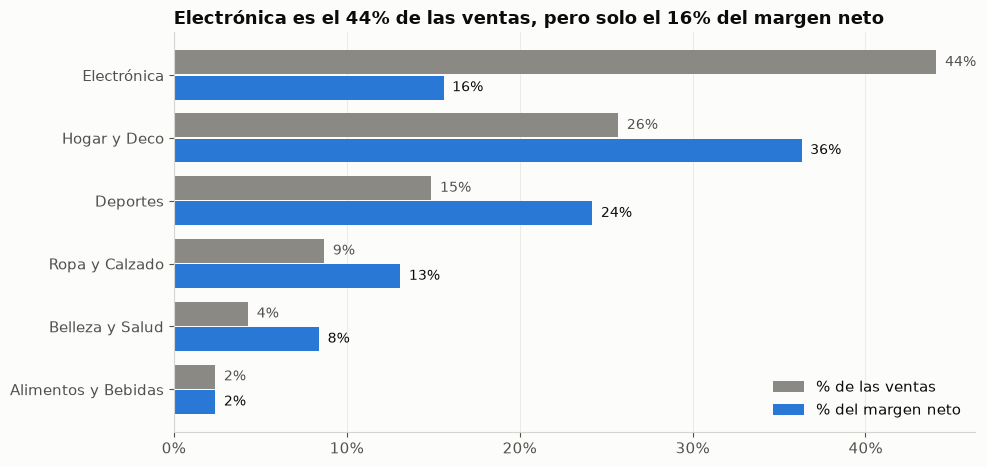

In [6]:
# Gráfico: % de las ventas contra % del margen neto, por categoría
t = tablas["categoria"].sort_values("% de las ventas")
y = np.arange(len(t))
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(y + 0.2, t["% de las ventas"], height=0.38, color=GRIS, label="% de las ventas")
ax.barh(y - 0.2, t["% del margen neto"], height=0.38, color=AZUL, label="% del margen neto")
for i, (v, m) in enumerate(zip(t["% de las ventas"], t["% del margen neto"])):
    ax.text(v + 0.5, i + 0.2, f"{v:.0f}%", va="center", color=TEXTO_2, fontsize=10)
    ax.text(m + 0.5, i - 0.2, f"{m:.0f}%", va="center", color=TEXTO, fontsize=10)
ax.set_yticks(y, [c.replace("_", " ") for c in t.index])
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0f}%")
e = tablas["categoria"].loc["Electrónica"]
ax.set_title(f"Electrónica es el {e['% de las ventas']:.0f}% de las ventas, pero solo el {e['% del margen neto']:.0f}% del margen neto")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a2_categorias_ventas_vs_margen.png", dpi=200)
plt.show()

## 3. Valor del cliente a lo largo del tiempo (CLV)

**Cómo lo calculamos:** CLV = margen neto de un semestre × (1 + r + r² + … + r⁵), donde r es la retención semestral. Es el margen que se espera que deje un cliente en los próximos 3 años (6 semestres) si sigue comprando al mismo ritmo.

- **Margen de un semestre:** margen neto promedio de los clientes del segmento que compraron en ese semestre.
- **Retención semestral (r):** de los clientes que compraron en un semestre, qué porcentaje volvió a comprar en el siguiente.

Usamos semestres y no años porque con 2 años de datos solo hay un paso de un año al siguiente. Con semestres hay tres (2023-S1→S2, 2023-S2→2024-S1 y 2024-S1→S2), y eso permite ver si el CLV cae con el tiempo. Al final comprobamos que la versión anual ordena los segmentos igual.

**Cuándo decimos que un segmento está en declive:** cuando el CLV de 2024 es menor que el de 2023 y la caída se sostiene al remuestrear los clientes 1.000 veces (*bootstrap*). Si el intervalo de confianza del 95% incluye el 0, la diferencia puede ser casualidad y no la llamamos declive.

**Una advertencia sobre el segmento del archivo.** Como el segmento se asignó contando las compras de los 24 meses (A1.4), su retención está en parte determinada de antemano: un "Inactivo" tiene como mucho una compra, así que su retención es 0 por definición, y un "Premium" tiene al menos 4, así que casi siempre vuelve. Por eso, además del CLV por segmento (lo que pide el enunciado), lo calculamos con **grupos que se conocen en el semestre base**: cuántas veces compró el cliente en ese semestre. Esa versión sí es una predicción.

In [7]:
# Semestres y clientes activos en cada uno
trx["semestre"] = trx.fecha.dt.year.astype(str) + "-S" + np.where(trx.fecha.dt.month <= 6, "1", "2")
SEMESTRES = sorted(trx.semestre.unique())
margen_sem = trx.groupby(["cliente_id", "semestre"]).margen_neto.sum().unstack(fill_value=0)
activo = trx.groupby(["cliente_id", "semestre"]).size().unstack(fill_value=0) > 0
segmento = cli.set_index("cliente_id").segmento.reindex(activo.index)

HORIZONTE = 6  # semestres = 3 años

def clv(ids, base, siguiente):
    # CLV a 3 años de los clientes activos en el semestre base
    act = activo.loc[ids, base]
    if act.sum() == 0:
        return np.nan, np.nan, np.nan
    m = margen_sem.loc[ids, base][act].mean()
    r = activo.loc[ids, siguiente][act].mean()
    return m * sum(r ** k for k in range(HORIZONTE)), m, r

filas = []
for seg in sorted(segmento.unique()):
    ids = segmento.index[segmento == seg]
    for base, sig in zip(SEMESTRES, SEMESTRES[1:]):
        valor, m, r = clv(ids, base, sig)
        filas.append({"segmento": seg, "periodo": f"{base} → {sig}", "margen por semestre": m,
                      "retención semestral %": 100 * r, "CLV 3 años": valor})
clv_tabla = pd.DataFrame(filas)
print(clv_tabla.pivot(index="segmento", columns="periodo", values="CLV 3 años").round(0).to_string())
print()
print(clv_tabla.pivot(index="segmento", columns="periodo", values="retención semestral %").round(1).to_string())
print()
print(clv_tabla.pivot(index="segmento", columns="periodo", values="margen por semestre").round(1).to_string())

periodo     2023-S1 → 2023-S2  2023-S2 → 2024-S1  2024-S1 → 2024-S2
segmento                                                           
Esporádico              152.0              148.0              145.0
Frecuente               845.0              884.0              851.0
Inactivo                 68.0               51.0               57.0
Nuevo                    78.0               84.0               90.0
Premium                1744.0             1910.0             1828.0

periodo     2023-S1 → 2023-S2  2023-S2 → 2024-S1  2024-S1 → 2024-S2
segmento                                                           
Esporádico               48.4               47.1               47.2
Frecuente                92.9               92.5               93.4
Inactivo                  0.0                0.0                0.0
Nuevo                    12.1               14.5               13.7
Premium                  99.0               99.4               98.8

periodo     2023-S1 → 2023-S2  2023-S2 → 2024-

In [8]:
# ¿Hay declive? Diferencia entre el último periodo y el primero, con intervalo de confianza por bootstrap
rng = np.random.default_rng(42)
primero, ultimo = (SEMESTRES[0], SEMESTRES[1]), (SEMESTRES[2], SEMESTRES[3])
res = []
for seg in sorted(segmento.unique()):
    ids = np.asarray(segmento.index[segmento == seg])
    base = clv(ids, *ultimo)[0] - clv(ids, *primero)[0]
    difs = []
    for _ in range(1000):
        muestra = rng.choice(ids, size=len(ids), replace=True)
        difs.append(clv(muestra, *ultimo)[0] - clv(muestra, *primero)[0])
    lo, hi = np.nanpercentile(difs, [2.5, 97.5])
    inicial = clv(ids, *primero)[0]
    res.append({"segmento": seg, "CLV 2023 (S1→S2)": inicial, "CLV 2024 (S1→S2)": inicial + base,
                "cambio %": 100 * base / inicial, "IC 95% bajo %": 100 * lo / inicial, "IC 95% alto %": 100 * hi / inicial,
                "¿declive?": "sí" if hi < 0 else "no"})
declive = pd.DataFrame(res).set_index("segmento").round(1)
declive

,CLV 2023 (S1→S2),CLV 2024 (S1→S2),cambio %,IC 95% bajo %,IC 95% alto %,¿declive?
segmento,,,,,,
Esporádico,151.8,144.7,-4.6,-25.2,15.9,no
Frecuente,845.4,851.0,0.7,-10.3,11.5,no
Inactivo,68.0,57.2,-15.9,-64.3,32.4,no
Nuevo,77.9,89.5,14.9,-17.5,48.3,no
Premium,1743.6,1828.2,4.9,-7.8,17.2,no


In [9]:
# Contraste: CLV con el segmento calculado en A1 (último periodo)
rfm = cli.set_index("cliente_id").segmento_rfm.reindex(activo.index)
contraste = {s: clv(rfm.index[rfm == s], *ultimo)[0] for s in sorted(rfm.dropna().unique())}
print("CLV 3 años con el segmento calculado:", {k: round(v) for k, v in contraste.items() if not np.isnan(v)})

# Comprobación con la versión anual (2023 → 2024)
a23 = trx[trx.anio == 2023].groupby("cliente_id").margen_neto.sum()
a24 = set(trx[trx.anio == 2024].cliente_id)
anual = pd.DataFrame({"m": a23, "seg": segmento.reindex(a23.index), "vuelve": a23.index.isin(a24)})
anual = anual.groupby("seg").agg(m=("m", "mean"), r=("vuelve", "mean"))
anual["CLV 3 años (anual)"] = anual.m * (1 + anual.r + anual.r ** 2)
print((anual.assign(r=100 * anual.r)).round(1).to_string())

CLV 3 años con el segmento calculado: {'Esporádico': 464, 'Frecuente': 1029, 'Inactivo': 97, 'Premium': 1948}
                m      r  CLV 3 años (anual)
seg                                         
Esporádico  104.2   77.7               248.1
Frecuente   321.7   99.3               958.3
Inactivo     59.0    0.0                59.0
Nuevo        74.3   32.0               105.7
Premium     615.1  100.0              1845.4


In [10]:
# CLV con grupos conocidos en el semestre base: número de compras en ese semestre
GRUPOS = ["1 compra", "2–3", "4–6", "7 o más"]
compras_sem = trx.groupby(["cliente_id", "semestre"]).size().unstack(fill_value=0)

def grupo_base(base):
    act = compras_sem[base] > 0
    return pd.cut(compras_sem.loc[act, base], [0, 1, 3, 6, 10_000], labels=GRUPOS)

def clv_grupo(ids, base, siguiente, tasa_anual=0.0):
    m = margen_sem.loc[ids, base].mean()
    r = activo.loc[ids, siguiente].mean()
    q = (1 + tasa_anual) ** 0.5 - 1  # tasa semestral
    return m * sum((r / (1 + q)) ** k for k in range(HORIZONTE)), m, r

filas = []
for base, sig in zip(SEMESTRES, SEMESTRES[1:]):
    g = grupo_base(base)
    for nombre in GRUPOS:
        ids = g.index[g == nombre]
        valor, m, r = clv_grupo(ids, base, sig)
        filas.append({"grupo": nombre, "periodo": f"{base} → {sig}", "clientes": len(ids), "retención %": 100 * r, "CLV 3 años": valor})
clv_grupos = pd.DataFrame(filas)
print(clv_grupos.pivot(index="grupo", columns="periodo", values="CLV 3 años").round(0).to_string())
print()
print(clv_grupos.pivot(index="grupo", columns="periodo", values="retención %").round(1).to_string())

# Declive con los grupos: 2024 (S1→S2) contra 2023 (S1→S2), bootstrap dentro de cada grupo
res = []
g23, g24 = grupo_base(primero[0]), grupo_base(ultimo[0])
for nombre in GRUPOS:
    i23, i24 = np.asarray(g23.index[g23 == nombre]), np.asarray(g24.index[g24 == nombre])
    v23, v24 = clv_grupo(i23, *primero)[0], clv_grupo(i24, *ultimo)[0]
    difs = [clv_grupo(rng.choice(i24, len(i24)), *ultimo)[0] - clv_grupo(rng.choice(i23, len(i23)), *primero)[0] for _ in range(1000)]
    lo, hi = np.percentile(difs, [2.5, 97.5])
    res.append({"grupo": nombre, "CLV 2023": v23, "CLV 2024": v24, "cambio %": 100 * (v24 / v23 - 1),
                "IC 95% bajo %": 100 * lo / v23, "IC 95% alto %": 100 * hi / v23, "¿declive?": "sí" if hi < 0 else "no"})
declive_grupos = pd.DataFrame(res).set_index("grupo").round(1)
declive_grupos

periodo   2023-S1 → 2023-S2  2023-S2 → 2024-S1  2024-S1 → 2024-S2
grupo                                                            
1 compra              128.0              118.0              122.0
2–3                   518.0              579.0              513.0
4–6                  1537.0             1609.0             1535.0
7 o más              3012.0             3044.0             3094.0

periodo   2023-S1 → 2023-S2  2023-S2 → 2024-S1  2024-S1 → 2024-S2
grupo                                                            
1 compra               52.9               52.3               51.6
2–3                    80.6               80.5               80.5
4–6                    94.2               94.5               94.8
7 o más                98.9               97.6               98.0


,CLV 2023,CLV 2024,cambio %,IC 95% bajo %,IC 95% alto %,¿declive?
grupo,,,,,,
1 compra,128.4,121.6,-5.3,-21.9,11.1,no
2–3,517.6,512.8,-0.9,-14.9,13.3,no
4–6,1537.4,1535.0,-0.2,-11.6,11.8,no
7 o más,3011.8,3093.5,2.7,-15.5,21.6,no


In [11]:
# Sensibilidad a la tasa de descuento (último periodo): ¿cambia el orden?
sens = {}
for tasa in [0.0, 0.10, 0.20]:
    col = f"tasa {tasa:.0%}"
    activos = activo.index[activo[ultimo[0]]]
    sens[col] = {seg: clv_grupo(activos[segmento.reindex(activos) == seg], *ultimo, tasa_anual=tasa)[0] for seg in sorted(segmento.unique())}
    g = grupo_base(ultimo[0])
    sens[col].update({nombre: clv_grupo(g.index[g == nombre], *ultimo, tasa_anual=tasa)[0] for nombre in GRUPOS})
pd.DataFrame(sens).round(0)

,tasa 0%,tasa 10%,tasa 20%
Esporádico,145.0,139.0,135.0
Frecuente,851.0,765.0,698.0
Inactivo,57.0,57.0,57.0
Nuevo,90.0,89.0,88.0
Premium,1828.0,1631.0,1478.0
1 compra,122.0,116.0,112.0
2–3,513.0,470.0,437.0
4–6,1535.0,1377.0,1255.0
7 o más,3094.0,2763.0,2506.0


**Resultado de las comprobaciones:**
- **Con grupos que se conocen de antemano, el CLV cuenta la misma historia.** Un cliente que compra una vez en un semestre vuelve el semestre siguiente un 52% de las veces y deja unas 122 u. m. en 3 años. Uno que compra de 4 a 6 veces vuelve un 95% de las veces y deja unas 1.535, unas 13 veces más. La relación "más compras → mucho más valor" no es un efecto de cómo se definió el segmento.
- **Tampoco hay declive con los grupos.** El CLV y la retención de cada grupo son casi iguales en los tres periodos.
- **"Ningún segmento en declive" quiere decir "no detectable", no "seguro que no".** Con el segmento del archivo, el intervalo de confianza deja pasar caídas de hasta 10% (Frecuente), 8% (Premium) y 25% (Esporádico). En Nuevo e Inactivo, los grupos son tan pequeños que solo se detectarían caídas de más de 17% y 64%.
- **Tasa de descuento.** No la usamos en la cifra principal porque en Venezuela, con inflación alta, no hay una tasa de referencia fácil de justificar. Con inflación, la tasa debería ser alta, no cero. Por eso mostramos el CLV con 10% y 20% anual: los valores bajan, pero el orden de los segmentos y de los grupos no cambia.
- **El "13 veces" del gráfico.** Con el segmento del archivo, un Premium deja 13 veces más que un Esporádico; con la versión anual, 7 veces. Es la misma comparación medida de otra forma, pero el segmento exagera la distancia. En el gráfico usamos los grupos de compras, que no dependen de cómo se definió el segmento.

In [12]:
# ¿Llegan cada vez menos clientes nuevos, o es que se agotan los clientes del archivo?
primera = trx.groupby("cliente_id").fecha.min().dt.to_period("Q")
trimestres = sorted(primera.unique())
filas = []
pendientes = len(cli)  # clientes del archivo que todavía no han comprado
for q in trimestres:
    nuevos = (primera == q).sum()
    filas.append({"trimestre": str(q), "primeras compras": nuevos, "clientes sin comprar aún": pendientes,
                  "% que compra por primera vez": 100 * nuevos / pendientes})
    pendientes -= nuevos
nuevos_q = pd.DataFrame(filas).set_index("trimestre").round(1)
nuevos_q

,primeras compras,clientes sin comprar aún,% que compra por primera vez
trimestre,,,
2023Q1,3499,8000,43.7
2023Q2,1427,4501,31.7
2023Q3,778,3074,25.3
2023Q4,617,2296,26.9
2024Q1,457,1679,27.2
2024Q2,334,1222,27.3
2024Q3,278,888,31.3
2024Q4,218,610,35.7


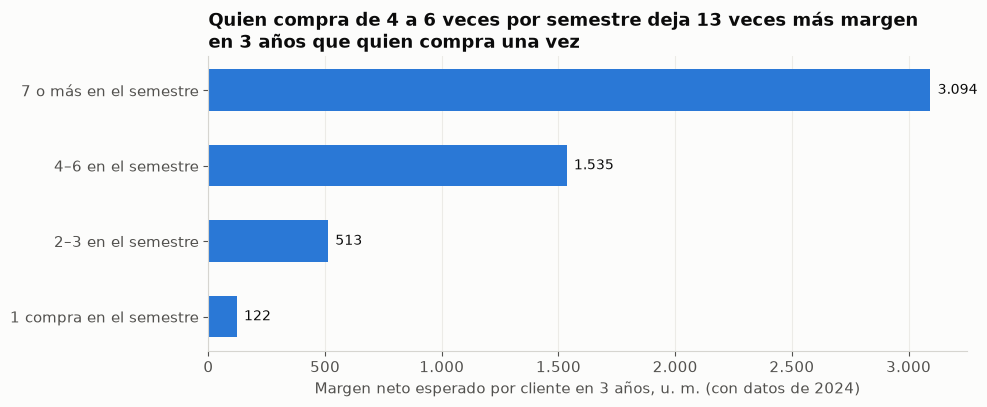

In [13]:
# Gráfico: CLV por número de compras en el semestre (grupos conocidos de antemano, último periodo)
dg = declive_grupos.reindex(GRUPOS)
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(dg))
ax.barh(y, dg["CLV 2024"], height=0.55, color=AZUL)
for i, v in enumerate(dg["CLV 2024"]):
    ax.text(v + dg["CLV 2024"].max() * 0.01, i, miles(v), va="center", color=TEXTO, fontsize=10)
ax.set_yticks(y, [f"{g} en el semestre" for g in dg.index])
ax.xaxis.set_major_formatter(lambda x, _: miles(x))
veces = declive_grupos.loc["4–6", "CLV 2024"] / declive_grupos.loc["1 compra", "CLV 2024"]
ax.set_title(f"Quien compra de 4 a 6 veces por semestre deja {veces:.0f} veces más margen\nen 3 años que quien compra una vez")
ax.set_xlabel("Margen neto esperado por cliente en 3 años, u. m. (con datos de 2024)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a2_clv_grupos.png", dpi=200)
plt.show()

## 4. Estacionalidad

Para cada categoría y cada canal buscamos el mes pico (el que más vende, en promedio de 2023 y 2024), el mes valle (el que menos vende) y la tendencia (cuánto crecen o bajan las ventas por año).

Después comprobamos si esos picos y valles son reales o casualidad:

- **¿El patrón se repite?** Si un mes es pico por una razón real (Navidad, regreso a clases), debería serlo en los dos años. Lo medimos con la correlación entre el perfil mensual de 2023 y el de 2024: cerca de 1, se repite; cerca de 0 o negativa, no.
- **¿Algún mes vende distinto?** Con la prueba de Kruskal-Wallis comparamos las ventas diarias de los 12 meses. Si p es mayor que 0,05, no hay evidencia de que algún mes venda distinto.
- **¿La tendencia es real?** Si el intervalo de confianza de la tendencia incluye el 0, no podemos decir que las ventas suban o bajen.

In [14]:
def estacionalidad(col):
    mensual = trx.groupby([col, "mes"]).monto_neto.sum().unstack(0)
    filas = []
    for g in mensual.columns:
        s = mensual[g]
        por_mes = s.groupby(s.index.month).mean()
        indice = 100 * por_mes / por_mes.mean()
        a23 = s[s.index.year == 2023].values
        a24 = s[s.index.year == 2024].values
        t = np.arange(len(s))
        ajuste = stats.linregress(t, s.values)
        pendiente_anual = 100 * ajuste.slope * 12 / s.mean()
        ic = 100 * 1.96 * ajuste.stderr * 12 / s.mean()
        filas.append({col: g, "mes pico": int(indice.idxmax()), "índice pico": indice.max(),
                      "mes valle": int(indice.idxmin()), "índice valle": indice.min(),
                      "¿se repite? (corr. 2023 vs 2024)": np.corrcoef(a23, a24)[0, 1],
                      "tendencia %/año": pendiente_anual, "IC 95% ±": ic})
    return pd.DataFrame(filas).set_index(col).round(2)

print(estacionalidad("categoria").to_string())
print()
print(estacionalidad("canal").to_string())

                     mes pico  índice pico  mes valle  índice valle  ¿se repite? (corr. 2023 vs 2024)  tendencia %/año  IC 95% ±
categoria                                                                                                                       
Alimentos_y_Bebidas         1       106.97         11         93.43                             -0.25            -0.54      4.78
Belleza_y_Salud             7       109.51          2         93.99                             -0.35             2.85      5.25
Deportes                   10       109.54          4         89.51                              0.21            -0.46      5.52
Electrónica                 5       107.70          2         86.74                              0.29             0.39      5.86
Hogar_y_Deco                4       106.72          1         92.02                              0.15             0.77      5.08
Ropa_y_Calzado              3       113.85          2         88.32                              

In [15]:
diario = trx.groupby("fecha").monto_neto.sum()
grupos = [diario[diario.index.month == m].values for m in range(1, 13)]
h, p = stats.kruskal(*grupos)
print(f"Kruskal-Wallis, ventas diarias por mes (total): H = {h:.1f}, p = {p:.3f}")
indice_total = diario.groupby(diario.index.month).mean()
print("Índice mensual total (100 = mes promedio):", (100 * indice_total / indice_total.mean()).round(0).astype(int).to_dict())

dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
por_dia = diario.groupby(diario.index.dayofweek).mean()
print("Venta diaria promedio por día de la semana:", dict(zip(dias, por_dia.round(0).astype(int))))
h, p = stats.kruskal(*[diario[diario.index.dayofweek == k].values for k in range(7)])
print(f"Kruskal-Wallis por día de la semana: p = {p:.3f}")

mensual_total = trx.groupby("mes").monto_neto.sum()
ajuste = stats.linregress(np.arange(24), mensual_total.values)
print(f"Tendencia de las ventas totales: {100 * ajuste.slope * 12 / mensual_total.mean():.1f}% por año (p = {ajuste.pvalue:.2f})")
print("Ventas 2023 vs 2024 por categoría (cambio %):",
      (100 * (trx[trx.anio == 2024].groupby("categoria").monto_neto.sum() / trx[trx.anio == 2023].groupby("categoria").monto_neto.sum() - 1)).round(1).to_dict())
print("Margen bruto 2023 vs 2024 por categoría (cambio %):",
      (100 * (trx[trx.anio == 2024].groupby("categoria").margen_bruto.sum() / trx[trx.anio == 2023].groupby("categoria").margen_bruto.sum() - 1)).round(1).to_dict())

Kruskal-Wallis, ventas diarias por mes (total): H = 8.9, p = 0.630
Índice mensual total (100 = mes promedio): {1: 95, 2: 99, 3: 103, 4: 100, 5: 103, 6: 97, 7: 101, 8: 100, 9: 102, 10: 101, 11: 101, 12: 98}
Venta diaria promedio por día de la semana: {'lun': 24027, 'mar': 23771, 'mié': 23687, 'jue': 24037, 'vie': 24013, 'sáb': 23661, 'dom': 23360}
Kruskal-Wallis por día de la semana: p = 0.985
Tendencia de las ventas totales: 0.7% por año (p = 0.71)
Ventas 2023 vs 2024 por categoría (cambio %): {'Alimentos_y_Bebidas': 1.6, 'Belleza_y_Salud': 2.8, 'Deportes': -0.8, 'Electrónica': -2.0, 'Hogar_y_Deco': 1.4, 'Ropa_y_Calzado': 2.9}
Margen bruto 2023 vs 2024 por categoría (cambio %): {'Alimentos_y_Bebidas': 3.6, 'Belleza_y_Salud': 2.2, 'Deportes': 0.3, 'Electrónica': -2.6, 'Hogar_y_Deco': 1.9, 'Ropa_y_Calzado': 3.4}


## 5. ¿Los descuentos compensan el margen que regalan?

Un descuento baja el margen de cada venta. Para que valga la pena, tiene que hacer que la gente compre más. Lo comprobamos de cuatro formas:

1. **Por nivel de descuento:** unidades por compra y margen para cada banda de descuento.
2. **Volumen necesario contra volumen real:** si un producto deja un margen g a precio de lista y se le da un descuento d, hay que vender d / (g − d) más unidades para ganar lo mismo. Lo comparamos con lo que de verdad se vendió de más.
3. **Regresión:** el efecto del descuento sobre las unidades por compra, dejando fijos la categoría, el canal y el segmento. Así evitamos confundir el efecto del descuento con el de, por ejemplo, vender más online.
4. **Frecuencia:** si los clientes que reciben más descuento compran más veces, y si el mismo producto vende más en los meses con más descuento.
5. **Recompra:** si una compra con más descuento hace que el cliente vuelva antes. Es la pregunta clave para saber si bajar un descuento espanta clientes: las cuatro anteriores solo miran ventas que sí ocurrieron.

In [16]:
trx["banda"] = pd.cut(trx.descuento, [-0.001, 0, 0.05, 0.10, 0.20, 0.35],
                      labels=["sin descuento", "hasta 5%", "5% a 10%", "10% a 20%", "más de 20%"])
bandas = trx.groupby("banda", observed=True).agg(
    compras=("transaccion_id", "size"),
    unidades_por_compra=("cantidad", "mean"),
    descuento_medio=("descuento", "mean"),
    margen_por_compra=("margen_bruto", "mean"),
    ventas=("monto_neto", "sum"),
    margen=("margen_bruto", "sum"),
    regalado=("costo_descuento", "sum"),
)
# Margen que tendría cada venta a precio de lista (sin descuento)
trx["margen_lista"] = 1 - trx.costo_total / (trx.cantidad * trx.precio_unitario)
bandas["margen_lista"] = trx.groupby("banda", observed=True).margen_lista.mean()
bandas["margen %"] = 100 * bandas.margen / bandas.ventas
# Volumen extra necesario para que el margen total no cambie: d / (g - d)
bandas["volumen extra necesario %"] = 100 * bandas.descuento_medio / (bandas.margen_lista - bandas.descuento_medio)
bandas["volumen extra real %"] = 100 * (bandas.unidades_por_compra / bandas.loc["sin descuento", "unidades_por_compra"] - 1)
bandas.drop(columns=["ventas", "margen"]).round(2)

,compras,unidades_por_compra,descuento_medio,margen_por_compra,regalado,margen_lista,margen %,volumen extra necesario %,volumen extra real %
banda,,,,,,,,,
sin descuento,14660,1.78,0.00,105.28,0.00,0.34,28.81,0.00,0.00
hasta 5%,16922,1.78,0.02,96.35,150266.13,0.34,27.18,7.60,-0.05
5% a 10%,8903,1.78,0.07,77.81,232077.57,0.34,22.92,26.33,-0.18
10% a 20%,7637,1.79,0.15,53.16,423827.39,0.34,16.45,74.74,0.47
más de 20%,1878,1.79,0.23,20.09,161529.98,0.34,6.89,207.04,0.52


In [17]:
modelo = smf.ols("cantidad ~ descuento + C(categoria) + C(canal) + C(segmento)", data=trx).fit()
coef, (lo, hi) = modelo.params["descuento"], modelo.conf_int().loc["descuento"]
print(f"Efecto del descuento sobre las unidades por compra (controlando categoría, canal y segmento):")
print(f"   +10 puntos de descuento → {coef * 0.10:+.3f} unidades (IC 95%: {lo * 0.10:+.3f} a {hi * 0.10:+.3f}), p = {modelo.pvalues['descuento']:.2f}")

# ¿Los clientes que reciben más descuento compran más veces?
por_cliente = trx.groupby(["cliente_id", "segmento"]).agg(compras=("transaccion_id", "size"), descuento=("descuento", "mean")).reset_index()
for seg, g in por_cliente.groupby("segmento"):
    if g.compras.nunique() > 1:
        rho, p = stats.spearmanr(g.descuento, g.compras)
        print(f"   {seg:11s} correlación descuento medio vs número de compras: {rho:+.3f} (p = {p:.2f})")

# ¿Los meses con más descuento en un producto venden más unidades?
pm = trx.groupby(["producto_id", "mes"]).agg(unidades=("cantidad", "sum"), descuento=("descuento", "mean")).reset_index()
pm["unidades_rel"] = pm.unidades / pm.groupby("producto_id").unidades.transform("mean")
pm["descuento_rel"] = pm.descuento - pm.groupby("producto_id").descuento.transform("mean")
rho, p = stats.spearmanr(pm.descuento_rel, pm.unidades_rel)
print(f"Mismo producto, meses con más descuento vs unidades vendidas: correlación {rho:+.3f} (p = {p:.2f})")

Efecto del descuento sobre las unidades por compra (controlando categoría, canal y segmento):
   +10 puntos de descuento → +0.004 unidades (IC 95%: -0.012 a +0.020), p = 0.63
   Esporádico  correlación descuento medio vs número de compras: +0.050 (p = 0.01)
   Frecuente   correlación descuento medio vs número de compras: +0.012 (p = 0.56)
   Nuevo       correlación descuento medio vs número de compras: +0.085 (p = 0.02)
   Premium     correlación descuento medio vs número de compras: +0.061 (p = 0.09)
Mismo producto, meses con más descuento vs unidades vendidas: correlación +0.020 (p = 0.08)


In [18]:
# ¿Hay promociones? Si el descuento se diera por campañas (un producto rebajado un mes entero), el descuento medio
# de cada producto variaría entre meses más que si el descuento se repartiera al azar entre sus ventas. Lo comparamos con 200 permutaciones.
rng_p = np.random.default_rng(7)
def var_entre_meses(desc):
    return trx.assign(x=desc).groupby(["producto_id", "mes"]).x.mean().groupby(level=0).var().mean()
observada = var_entre_meses(trx.descuento.values)
permutadas = np.array([var_entre_meses(trx.groupby("producto_id").descuento.transform(lambda s: rng_p.permutation(s.values)).values)
                       for _ in range(200)])
print(f"Variación del descuento entre meses: real {observada:.6f} | al azar {permutadas.mean():.6f} "
      f"(95%: {np.percentile(permutadas, 2.5):.6f} a {np.percentile(permutadas, 97.5):.6f}) | p = {(permutadas >= observada).mean():.2f}")

# ¿Una compra con más descuento hace que el cliente vuelva antes? Recompra en 90 días, solo compras con 90 días de datos por delante
dias_cliente = trx[["cliente_id", "fecha"]].drop_duplicates().sort_values(["cliente_id", "fecha"])
dias_cliente["siguiente"] = dias_cliente.groupby("cliente_id").fecha.shift(-1)
rc = trx.merge(dias_cliente, on=["cliente_id", "fecha"])
rc = rc[rc.fecha <= trx.fecha.max() - pd.Timedelta(days=90)].copy()
rc["vuelve_90"] = ((rc.siguiente - rc.fecha).dt.days <= 90).astype(int)
m_rc = smf.ols("vuelve_90 ~ descuento + C(canal) * C(segmento) + C(categoria)", data=rc).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(rc.cliente_id)[0]})
ef, (lo, hi) = m_rc.params["descuento"] * 0.10, m_rc.conf_int().loc["descuento"] * 0.10
print(f"Recompra en 90 días: {rc.vuelve_90.mean():.1%} de las compras ({len(rc):,} compras)")
print(f"   +10 puntos de descuento → {100 * ef:+.2f} puntos de recompra (IC 95%: {100 * lo:+.2f} a {100 * hi:+.2f}), "
      f"controlando canal × segmento y categoría")

# La correlación de Esporádico y Nuevo, ¿se debe a que compran más online (donde hay más descuento)?
trx["descuento_vs_canal"] = trx.descuento - trx.groupby("canal").descuento.transform("mean")
pc = trx.groupby(["cliente_id", "segmento"]).agg(compras=("transaccion_id", "size"), d=("descuento_vs_canal", "mean")).reset_index()
for seg, g in pc.groupby("segmento"):
    if g.compras.nunique() > 1:
        rho, p = stats.spearmanr(g.d, g.compras)
        print(f"   {seg:11s} correlación sin el efecto del canal: {rho:+.3f} (p = {p:.2f})")

Variación del descuento entre meses: real 0.000732 | al azar 0.000725 (95%: 0.000696 a 0.000757) | p = 0.31


Recompra en 90 días: 67.6% de las compras (43,845 compras)
   +10 puntos de descuento → +0.21 puntos de recompra (IC 95%: -0.43 a +0.85), controlando canal × segmento y categoría
   Esporádico  correlación sin el efecto del canal: +0.080 (p = 0.00)
   Frecuente   correlación sin el efecto del canal: +0.013 (p = 0.52)
   Nuevo       correlación sin el efecto del canal: +0.082 (p = 0.03)
   Premium     correlación sin el efecto del canal: +0.037 (p = 0.30)


**Resultado de las comprobaciones nuevas:**
- **No hay promociones.** El descuento medio de cada producto varía entre meses igual que si el descuento se repartiera al azar entre sus ventas (p = 0,3). El descuento cambia venta a venta, no por campañas. Por eso la prueba "mismo producto en meses con más descuento" no dice mucho: no hay meses con más descuento. Lo que sí sirve es comparar ventas sueltas con más y menos descuento, y eso es lo que hacen la regresión de unidades y la de recompra.
- **El descuento no hace volver antes al cliente.** El 68% de las compras va seguido de otra en 90 días. Con 10 puntos más de descuento, la recompra cambia +0,2 puntos (IC 95%: −0,4 a +0,9). Es decir, nada medible. Esto es lo más cercano que tenemos a la pregunta "si bajamos el descuento, ¿se van los clientes?".
- **La correlación débil de Esporádico y Nuevo no se explica por el canal** (sigue entre +0,05 y +0,08). Es una asociación entre clientes, muy débil, que no aparece cuando se mira compra a compra (la recompra no cambia con el descuento). No la usamos como evidencia.
- **Límite que no podemos cerrar:** los datos solo tienen las ventas que ocurrieron. Si un descuento menor hiciera que alguien no comprara nunca, no lo veríamos. Por eso, en A5, la recomendación sobre el descuento se propone como piloto.

In [19]:
print(f"Descuentos regalados en total: {regalado:,.0f}")
por_canal = trx.groupby("canal").costo_descuento.sum()
por_cat = trx.groupby("categoria").costo_descuento.sum()
print("Por canal (% del total):", (100 * por_canal / regalado).round(1).to_dict())
print("   % de las ventas de cada canal:", (100 * trx.groupby("canal").monto_neto.sum() / ventas).round(1).to_dict())
print("Por categoría (% del total):", (100 * por_cat / regalado).round(1).to_dict())
bc = trx[trx.bajo_costo]
print(f"Ventas bajo costo: {len(bc)}, pérdida {-bc.margen_bruto.sum():,.0f}; por canal:", bc.canal.value_counts().to_dict())
print("Descuento promedio por canal y año (%):")
print((100 * trx.groupby(["canal", "anio"]).descuento.mean().unstack()).round(2).to_string())

Descuentos regalados en total: 967,701
Por canal (% del total): {'app_movil': 12.4, 'online': 56.1, 'tienda_fisica': 31.5}
   % de las ventas de cada canal: {'app_movil': 17.2, 'online': 37.6, 'tienda_fisica': 45.2}
Por categoría (% del total): {'Alimentos_y_Bebidas': 2.3, 'Belleza_y_Salud': 4.2, 'Deportes': 15.4, 'Electrónica': 44.5, 'Hogar_y_Deco': 25.0, 'Ropa_y_Calzado': 8.5}
Ventas bajo costo: 711, pérdida 30,181; por canal: {'online': 441, 'tienda_fisica': 191, 'app_movil': 79}
Descuento promedio por canal y año (%):
anio           2023  2024
canal                    
app_movil      3.69  3.70
online         7.60  7.49
tienda_fisica  3.77  3.69


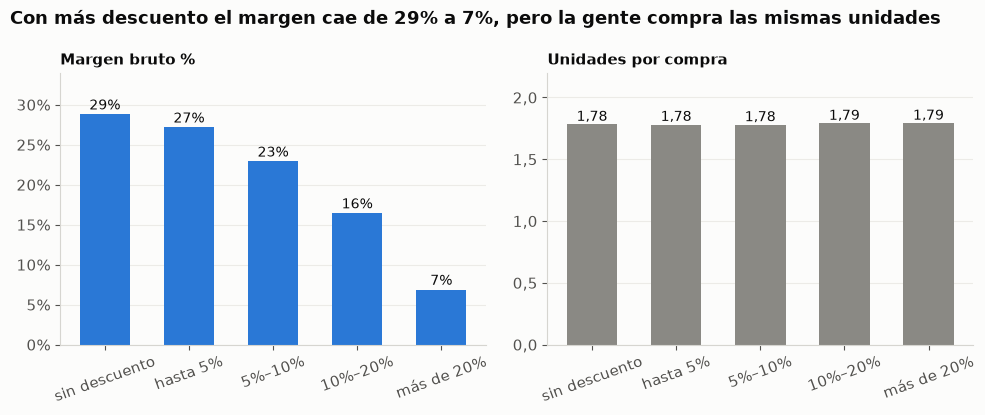

In [20]:
# Gráfico: margen por compra y unidades por compra según el descuento (dos paneles, sin doble eje)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
x = np.arange(len(bandas))
etiquetas = [b.replace(" a ", "–") for b in bandas.index.astype(str)]
a1.bar(x, bandas["margen %"], width=0.6, color=AZUL)
for i, v in enumerate(bandas["margen %"]):
    a1.text(i, v + 0.6, f"{v:.0f}%", ha="center", color=TEXTO, fontsize=10)
a1.set_xticks(x, etiquetas, rotation=20)
a1.set_title("Margen bruto %", fontsize=11)
a1.set_ylim(0, 34)
a1.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
a2.bar(x, bandas["unidades_por_compra"], width=0.6, color=GRIS)
for i, v in enumerate(bandas["unidades_por_compra"]):
    a2.text(i, v + 0.03, f"{v:.2f}".replace(".", ","), ha="center", color=TEXTO, fontsize=10)
a2.yaxis.set_major_formatter(lambda v, _: f"{v:.1f}".replace(".", ","))
a2.set_xticks(x, etiquetas, rotation=20)
a2.set_ylim(0, 2.2)
a2.set_title("Unidades por compra", fontsize=11)
for a in (a1, a2):
    a.grid(axis="x", visible=False)
fig.suptitle(f"Con más descuento el margen cae de {bandas['margen %'].iloc[0]:.0f}% a {bandas['margen %'].iloc[-1]:.0f}%, "
             "pero la gente compra las mismas unidades", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
fig.savefig(FIG / "a2_descuentos.png", dpi=200)
plt.show()

## 6. Resumen de A2

**Quién aporta el margen**
- **Categorías:** Hogar y Deco es la que más margen bruto aporta (31%). Electrónica es el 44% de las ventas, pero solo el 24% del margen bruto y el 16% del margen neto: tiene el margen más bajo (13,7%) y un 18% de sus ventas se devuelve. La que menos aporta es Alimentos y Bebidas (2%).
- **Canales:** la tienda física aporta el 47,5% del margen bruto; online, el 34,6%; la app, el 17,9%. Online tiene el margen más bajo (22,8%) porque da el doble de descuento (7,5% contra 3,7% en tienda y app).
- **Segmentos:** los Frecuentes aportan la mitad del margen bruto (49,5%) y los Premium, casi un tercio (31,2%). Los Inactivos (1,8%) y los Nuevos (1,9%) casi no aportan.
- **El margen no cae:** entre 24,6% y 25,4% todos los trimestres. El problema es de nivel, no de tendencia.
- **Devoluciones:** se llevan el 27,5% del margen bruto (13,5% si el proveedor asume los defectuosos). **Descuentos:** se llevan el 18,3% del margen que habría sin ellos.

**Valor del cliente (CLV a 3 años)**
- Por segmento del archivo, un cliente Premium deja 1.828 u. m. de margen neto en 3 años; uno Frecuente, 851; uno Esporádico, 145; uno Nuevo, 90; uno Inactivo, 57. Ese segmento se definió contando compras, así que exagera las distancias. Con grupos conocidos de antemano, quien compra 4–6 veces en un semestre deja unas 13 veces más que quien compra una vez (1.535 contra 122).
- **No hay declive detectable**, ni por segmento ni por grupos. Los cambios entre 2023 y 2024 van de −16% a +15%, y en todos el intervalo de confianza incluye el 0. Habríamos detectado caídas de más de 8–10% en Premium y Frecuente y de 25% en Esporádico; en Nuevo e Inactivo, solo caídas muy grandes.
- Con una tasa de descuento de 10% o 20% anual, los CLV bajan, pero el orden no cambia.
- Las primeras compras bajan de 3.499 (inicio de 2023) a 218 (fin de 2024), pero no porque lleguen menos clientes: el archivo tiene 8.000 clientes fijos y se van quedando sin clientes que no hayan comprado. De los que aún no habían comprado, entre el 25% y el 36% compra por primera vez cada trimestre, sin tendencia a la baja.

**Estacionalidad**
- Cada categoría y canal tiene un mes pico y un mes valle (ver la tabla de la sección 4), con diferencias de ±10% respecto a un mes normal.
- Pero **esos picos y valles no se repiten** de un año al otro (con solo dos años, es una prueba débil: basta para decir que no hay una estacionalidad marcada, no para descartar una pequeña) (correlación entre −0,35 y 0,33), ningún mes vende distinto (p = 0,63) y ningún día de la semana tampoco (p = 0,99). No hay estacionalidad: las diferencias entre meses son ruido.
- Tampoco hay tendencia: las ventas totales crecen 0,7% al año, y no es significativo (p = 0,71). Electrónica es la única categoría cuyo margen bruto baja de 2023 a 2024 (−2,6%). Es una caída pequeña, pero va en la misma dirección que el resto de sus problemas.

**Descuentos**
- **No compensan.** Con más descuento el margen cae de 29% a 7%, pero las unidades por compra son las mismas (1,78). Con un descuento de entre 10% y 20% habría que vender un 75% más de unidades para ganar lo mismo; con más de 20%, el triple. Y se vende igual.
- La regresión lo confirma: 10 puntos más de descuento suman +0,004 unidades por compra (IC 95%: −0,012 a +0,020), es decir, nada.
- El margen de lista es el mismo en todas las bandas de descuento (34%): los descuentos no se dan a productos más caros o más baratos. Eso hace más creíble que la falta de efecto sea real y no una casualidad de a qué productos se les dio descuento.
- **Una compra con más descuento no hace volver antes al cliente:** +0,2 puntos de recompra a 90 días por cada 10 de descuento (IC 95%: −0,4 a +0,9).
- No hay promociones: el descuento cambia venta a venta, como si se repartiera al azar.
- Los clientes que reciben más descuento compran apenas un poco más veces (correlación de 0,05 a 0,09, solo significativa en Esporádico y Nuevo). Es una asociación muy débil entre clientes, que no aparece compra a compra.
- **Límite:** solo vemos las ventas que ocurrieron. No podemos ver a alguien que no compró porque el descuento era menor.
- **Online** concentra el 56% de lo regalado en descuentos, con solo el 38% de las ventas. **Electrónica**, el 45%. Las 711 ventas bajo costo de A1 (441 de ellas online) suman 30.181 de pérdida.

**Títulos de gráfico candidatos para A5**
- "Electrónica es el 44% de las ventas, pero solo el 16% del margen neto" (`figures/a2_categorias_ventas_vs_margen.png`)
- "Quien compra de 4 a 6 veces en un semestre deja 13 veces más margen en 3 años que quien compra una vez" (`figures/a2_clv_grupos.png`)
- "Con más descuento el margen cae de 29% a 7%, pero la gente compra las mismas unidades" (`figures/a2_descuentos.png`)

In [21]:
# Tablas para el dashboard de Power BI (ver docs/dashboard.md)
from src.powerbi import guardar
guardar(declive.reset_index(), "resultado_a2_clv_segmento")
guardar(declive_grupos.reset_index(), "resultado_a2_clv_grupos")
guardar(margen_trimestre.reset_index(), "resultado_a2_margen_trimestre")